In [1]:
import numpy as np
import pymc as pm  # if using pymc >=4
import arviz as az
import matplotlib.pyplot as plt

plt.rcParams["svg.fonttype"] = "none"
import seaborn as sns

import pandas as pd

import json

from pytensor.tensor import cumsum
import pytensor.tensor as at

import os
from os import path
from glob import glob

import mvEEG.mvEEG as mvEEG

In [2]:
OVERWRITE = False
METRIC = "signedDprime"  # description for saving outputs, either "signedDprime" or "signedCorrWhite"
if METRIC == "signedCorrWhite":
    RESCALE = 1e6  # rescaling factor for RDMs to improve numerical stability in Bayesian models
else:
    RESCALE = 1  # if not rescaling, then set to 1 (i.e., no rescaling)

DROP_SS0 = True

In [3]:
Attn_possible_bends = [3, 4, 6, 8]
Attn_SS_to_idx = {1: 0, 2: 1, 3: 2, 4: 3, 6: 4, 8: 5}
Attn_idx_to_SS = {v: k for k, v in Attn_SS_to_idx.items()}

attn_plateau_percent = 0.05  # percent of growth after the bend that is considered to be the plateau
attn_total_size = 1 / (1 - attn_plateau_percent)
post_plateau_size = attn_total_size - 1
post_plateau_size, post_plateau_size / attn_total_size

(0.05263157894736836, 0.04999999999999995)

In [4]:
code_dict = {
    "A0": 10,
    "A1": 11,
    "A2": 12,
    "A3": 13,
    "A4": 14,
    "A6": 16,
    "A8": 18,
    "M0": 20,
    "M1": 21,
    "M2": 22,
    "M3": 23,
    "M4": 24,
    "M6": 26,
    "M8": 28,
}
conditions = list(code_dict.keys())

if DROP_SS0:
    conditions.remove("A0")
    conditions.remove("M0")

ridx, cidx = np.triu_indices(len(conditions), k=1)

ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan2"

wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans={},
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1200],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

delay_window = (wrangl.t > 300) & (
    wrangl.t < 1100
)  # time window to average distances over, only includes when probes could appear

In [5]:
with open("rejected_subs.json", "r") as f:
    rejected_subs = json.load(f)
rejected_subs

['19', '32', '33']

In [6]:
rdm_files = sorted(glob(f"../data/derivatives/*/RDMs/*desc-{METRIC}*npy"))
rdm_files = [f for f in rdm_files if f.split("-")[1].split("/")[0] not in rejected_subs]
rdm_files

['../data/derivatives/sub-01/RDMs/sub-01_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-02/RDMs/sub-02_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-03/RDMs/sub-03_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-04/RDMs/sub-04_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-05/RDMs/sub-05_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-06/RDMs/sub-06_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-07/RDMs/sub-07_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-08/RDMs/sub-08_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-09/RDMs/sub-09_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-10/RDMs/sub-10_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-11/RDMs/sub-11_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/derivatives/sub-12/RDMs/sub-12_task-banyan2_desc-signedDprime_rdm.npy',
 '../data/deriva

<Axes: >

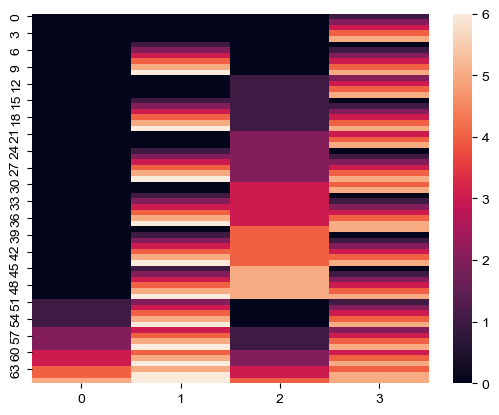

In [7]:
# Number of Items in WM
WM_setsizes = np.array([int(cond[1]) if (cond[0] == "M") else 0 for cond in conditions])
WMss_options = sorted(np.unique(WM_setsizes))
WM_setsize_map = {ss: i for i, ss in enumerate(WMss_options)}
cond_WMss_idx = np.array([WM_setsize_map[ss] for ss in WM_setsizes])

# Number of attended areas, assuming that people can filter our distractors
condition_ATTN = np.array([int(cond[1]) for cond in conditions])
ATTNss_options = sorted(np.unique(condition_ATTN))
ATTN_setsize_map = {ss: i for i, ss in enumerate(ATTNss_options)}
cond_ATTNss_idx = np.array([ATTN_setsize_map[ss] for ss in condition_ATTN])


q = np.array(
    [
        cond_WMss_idx[ridx],
        cond_WMss_idx[cidx],
        cond_ATTNss_idx[ridx],
        cond_ATTNss_idx[cidx],
    ]
).T

sns.heatmap(q)

# MODEL DEFINITION

In [8]:
def build_model(d, q, Attn_bend=None):
    """
    Build a model to estimate the WM and spatial attention functions with the following assumptions:
    1. The WM function is a guassian random walk, **is the same with or without placeholders**
    2. The spatial attention function is monotonic, **and is the same with or without placeholders**
    3. The stimulus energy function is monotonic

    **s indicate assumptions specific to this model

    Arguments
    ---------
    d : array of shape (n_distances,)
        The vectorized distances in upper (or lower) triangle of RDM
    q : array of shape (n_distances, n_regressors)
        Condition indices
    For this model the following column structure is expected:
    0. WM set size at first condition
    1. WM set size at second condition
    2. Spatial attention set size at first condition
    3. Spatial attention set size at second condition
    4. unique subject index for each distance (i.e., same for all distances from the same subject)

    """
    N = len(d)
    wmK = np.unique(q[:, :2]).size  # number of WM set sizes
    attnK = np.unique(q[:, 2:4]).size  # number of attended areas
    nsub = np.unique(q[:, 4]).size  # number of subjects

    # figure out where the plateau/bend occurs in the indices for each function, which determines how many values we need to estimate before the plateau
    # adding 1 to include the bend point itself. For example, if the bend is at SS4, then we need to estimate values for SS1, SS2, SS3, and SS4 (i.e., 4 values), and then the function plateaus (repeats) after that.
    attnMax = Attn_SS_to_idx[Attn_bend] + 1

    # check that the quad indices are in the expected format
    assert np.min(q) == 0
    assert q.shape[0] == N
    assert (np.max(q[:, :2]) + 1) == wmK
    assert (np.max(q[:, 2:4]) + 1) == attnK

    # steps between conditions we'd like to fit to data
    coords = {
        "innovations_num_WM": np.arange(1, wmK),
        "innovations_num_Attn": np.arange(1, attnK),
        "innovations_num_Attn_POP": np.arange(1, attnMax),
        "subject": np.arange(0, nsub),
        "trial_num": np.arange(1, N + 1),
    }

    with pm.Model(coords=coords) as model:

        # prior on noise in RDM values, used in likelihood below
        RDM_sigma_pop = pm.Exponential("RDM_sigma_pop", lam=5)  # OLD lam=10
        RDM_sigma_subs = pm.Exponential("RDM_sigma_subs", lam=1 / RDM_sigma_pop, dims=("subject",))

        # ~~~~~~~~~~~~ 1. Working Memory ~~~~~~~~~~~~
        mu_WM = pm.TruncatedNormal(
            "mu_WM", mu=0.5, sigma=0.25, lower=0, dims=("innovations_num_WM",)
        )  # population-level function values at each set size (except first, which is fixed to 0)

        sigma_lvls_prior_WM = pm.Exponential(
            "sigma_lvls_hyperprior_WM", lam=4
        )  # prior on variability of the subjects at each set size - setting it broad to include very small values
        sigma_lvls_WM = pm.Exponential("sigma_lvls_WM", scale=sigma_lvls_prior_WM, dims=("innovations_num_WM",))

        sub_vals_WM = pm.TruncatedNormal(
            "sub_vals_WM_minus_first",
            mu=mu_WM,
            sigma=sigma_lvls_WM,
            lower=0,
            dims=("subject", "innovations_num_WM"),
        )
        sub_vals_WM = pm.Deterministic("sub_vals_WM", at.concatenate((np.zeros((nsub, 1)), sub_vals_WM), axis=1))

        # ~~~~~~~~~~~~ 2. Spatial Attention ~~~~~~~~~~~~
        # define the population-level dirichlet prior
        pop_dir_Attn_to_bend = pm.Dirichlet(
            "pop_dir_Attn_to_bend", a=np.ones(attnMax - 1), dims=("innovations_num_Attn_POP",)
        )
        # get the final innovation for later model comparison
        mu_Attn_innov_final = pm.Deterministic(
            "mu_Attn_innov_final", cumsum(pop_dir_Attn_to_bend, axis=0)[-1] - cumsum(pop_dir_Attn_to_bend, axis=0)[-2]
        )
        # add extremely small values to the remaining set sizes after the bend.
        # note that the scale parameter means that the final steps won't stay at attn_min_step, but will still be proportionally very small
        post_plateau_n = attnK - attnMax
        if post_plateau_n > 0:
            post_plateau_step_size = post_plateau_size / post_plateau_n
            pop_dir_Attn = pm.Deterministic(
                "pop_dir_Attn",
                at.concatenate(
                    (pop_dir_Attn_to_bend, at.repeat(at.ones((1,)) * post_plateau_step_size, post_plateau_n)), axis=0
                ),
            )
        else:
            pop_dir_Attn = pm.Deterministic("pop_dir_Attn", pop_dir_Attn_to_bend)

        pop_dir_scale_Attn = pm.Exponential(
            "pop_dir_scale_Attn", lam=5
        )  # scale of dirichlet concentration, higher = less variance
        pop_concentration_Attn = pop_dir_scale_Attn * pop_dir_Attn

        # each subject's dirichlet is drawn from a scaled version of the population dirichlet
        sub_dir_Attn = pm.Dirichlet(
            "sub_dir_Attn",
            a=pop_concentration_Attn,
            dims=("subject", "innovations_num_Attn"),
        )
        sub_mu_Attn = pm.Deterministic("sub_mu_Attn_minus_first", cumsum(sub_dir_Attn, axis=1))
        sub_mu_Attn = pm.Deterministic("sub_mu_Attn", at.concatenate((np.zeros((nsub, 1)), sub_mu_Attn), axis=1))

        # subject scale is also hierarchical
        pop_scale_Attn = pm.Exponential("pop_scale_Attn", lam=5)
        sub_scale_Attn = pm.Exponential("sub_scale_Attn", lam=1 / pop_scale_Attn, dims=("subject",))

        # save the population function as a deterministic variable for later examination
        pop_mu_Attn = pm.Deterministic("pop_mu_Attn", pop_scale_Attn * cumsum(pop_dir_Attn, axis=0))

        # ~~~~~~~~~~~~ 3. Combine into full model ~~~~~~~~~~~~

        # start by getting difference scores between pairs of conds based on WM, Attn, and StimEnergy levels
        # WM
        mu_i_WM = sub_vals_WM[q[:, 4].astype(int), q[:, 0].astype(int)]
        mu_j_WM = sub_vals_WM[q[:, 4].astype(int), q[:, 1].astype(int)]
        mu_delta_WM = pm.math.abs(mu_i_WM - mu_j_WM)

        # NOTE: attn is flipped axes (subject, levels) compared to WM
        # Attn
        mu_i_Attn = sub_mu_Attn[q[:, 4].astype(int), q[:, 2].astype(int)]
        mu_j_Attn = sub_mu_Attn[q[:, 4].astype(int), q[:, 3].astype(int)]
        mu_delta_Attn = pm.math.abs(mu_i_Attn - mu_j_Attn) * sub_scale_Attn[q[:, 4].astype(int)]

        # likelihood function
        dist_est = mu_delta_WM + mu_delta_Attn
        pm.Normal("d", mu=dist_est, sigma=RDM_sigma_subs[q[:, 4].astype(int)], observed=d, dims=("trial_num",))

    return model

In [9]:
# build up distances and inputs

for i, f in enumerate(rdm_files):
    sub_id = f.split("-")[1].split("/")[0]
    sub_rdms = np.load(f)
    sub_rdm_delay = sub_rdms[..., delay_window].mean(-1)

    sub_dists = sub_rdm_delay[ridx, cidx] * RESCALE  # vectorize upper triangle, rescale for numerical stability

    sub_q = np.concatenate(
        [
            q,
            # np.array([[k_df.loc[sub_id, "high_k"]] * q.shape[0]]).T,  # add column to differentiate k groups
            np.array([[i] * q.shape[0]]).T,  # add column to index subjects
        ],
        axis=1,
    )

    if i == 0:
        pop_dists = sub_dists
        pop_q = sub_q
    else:
        pop_dists = np.concatenate((pop_dists, sub_dists))
        pop_q = np.concatenate((pop_q, sub_q), axis=0)

print(pop_dists.shape, pop_q.shape)

(1980,) (1980, 5)


# Run Model across different plateau points

In [10]:
for Attn_bend in Attn_possible_bends:
    model_fn = f"model_comparison/model_{METRIC}_AttnBend{Attn_bend}.nc"
    if path.exists(model_fn) and not OVERWRITE:
        print(f"Model with Attn bend {Attn_bend} already exists, skipping fit")
        continue

    print(f"Fitting model with Attn_bend={Attn_bend}")
    model = build_model(pop_dists, pop_q, Attn_bend=Attn_bend)

    # fit
    with model:
        idata = pm.sample(
            10_000,  # real samples per chain
            tune=10_000,  # warmup samples per chain
            chains=4,
            target_accept=0.9999,
            random_seed=2027,
            return_inferencedata=True,
            idata_kwargs={"log_likelihood": True},
            nuts_sampler="numpyro",
        )
        idata.extend(pm.sample_prior_predictive(40_000))  # add prior predictive samples to the idata for later checks
        # check for issues
        summary_table = az.summary(idata)
        if len(summary_table.loc[summary_table.r_hat > 1.01]) > 0:
            print(f"Model with Attn bend {Attn_bend} has convergence issues:")
            print(summary_table.loc[summary_table.r_hat > 1.01].head(100))  # print any parameters with r_hat > 1.01

    idata.to_netcdf(model_fn)

Model with Attn bend 3 already exists, skipping fit
Model with Attn bend 4 already exists, skipping fit
Model with Attn bend 6 already exists, skipping fit
Model with Attn bend 8 already exists, skipping fit


count    6.0
mean     1.0
std      0.0
min      1.0
25%      1.0
50%      1.0
75%      1.0
max      1.0
Name: r_hat, dtype: float64

count        6.000000
mean      9752.666667
std        625.856746
min       8791.000000
25%       9378.500000
50%      10151.000000
75%      10151.000000
max      10151.000000
Name: ess_bulk, dtype: float64

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_67195/985375257.py:19: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  lower = az.hdi(mu_Attn.T, hdi_prob=hdi_prob)[:, 0]
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_67195/985375257.py:20: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  upper = az.hdi(mu_Attn.T, hdi_prob=hdi_prob)[:, 1]
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_67195/985375257.py:35: RuntimeWarning: divide by zero encountered in scalar divide
  BF10 = np.sum(innov_pre <= attn_plateau_percent) / np.sum(innov_post <= attn_plateau_percent)


count    6.0
mean     1.0
std      0.0
min      1.0
25%      1.0
50%      1.0
75%      1.0
max      1.0
Name: r_hat, dtype: float64

count        6.000000
mean     26342.666667
std       7328.710819
min      12299.000000
25%      25568.750000
50%      29334.500000
75%      31094.000000
max      31094.000000
Name: ess_bulk, dtype: float64

...

count        6.000000
mean     45209.333333
std      21099.269975
min       9252.000000
25%      40945.500000
50%      44224.500000
75%      61567.500000
max      66354.000000
Name: ess_bulk, dtype: float64

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_67195/985375257.py:19: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  lower = az.hdi(mu_Attn.T, hdi_prob=hdi_prob)[:, 0]
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_67195/985375257.py:20: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  upper = az.hdi(mu_Attn.T, hdi_prob=hdi_prob)[:, 1]
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_67195/985375257.py:35: RuntimeWarning: divide by zero encountered in scalar divide
  BF10 = np.sum(innov_pre <= attn_plateau_percent) / np.sum(innov_post <= attn_plateau_percent)


count    6.0
mean     1.0
std      0.0
min      1.0
25%      1.0
50%      1.0
75%      1.0
max      1.0
Name: r_hat, dtype: float64

count        6.000000
mean     51048.666667
std      26735.876059
min       3506.000000
25%      46159.250000
50%      53818.000000
75%      66383.250000
max      80972.000000
Name: ess_bulk, dtype: float64

/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_67195/985375257.py:19: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  lower = az.hdi(mu_Attn.T, hdi_prob=hdi_prob)[:, 0]
/var/folders/g5/_50pp0f95mx6v6d1_3b33r700000gn/T/ipykernel_67195/985375257.py:20: FutureWarning: hdi currently interprets 2d data as (draw, shape) but this will change in a future release to (chain, draw) for coherence with other functions
  upper = az.hdi(mu_Attn.T, hdi_prob=hdi_prob)[:, 1]


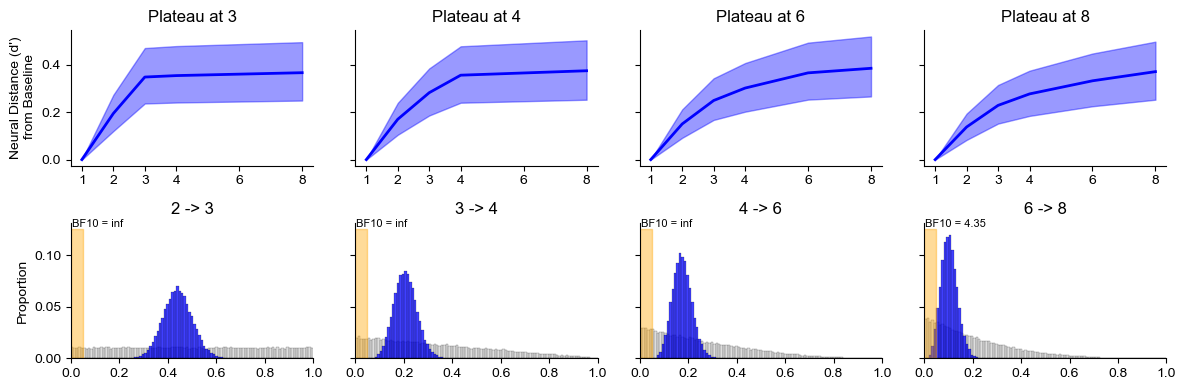

In [ ]:
fig, axes = plt.subplots(2, len(Attn_possible_bends), figsize=(3 * len(Attn_possible_bends), 4), sharey="row")

bfs = []
for i, Attn_bend in enumerate(Attn_possible_bends):
    model_fn = f"model_comparison/model_{METRIC}_AttnBend{Attn_bend}.nc"
    idata = az.from_netcdf(model_fn)
    # quite description of model fit
    curr_summary = az.summary(idata, var_names=["pop_mu_Attn", "mu_Attn_innov_final"])
    display(curr_summary.r_hat.describe())
    display(curr_summary.ess_bulk.describe())

    post = idata.posterior.stack(draws=("chain", "draw"))

    mu_Attn = post["pop_mu_Attn"].values
    mu_Attn = np.concatenate((np.zeros((1, mu_Attn.shape[1])), mu_Attn), axis=0)  # add 0 for set size 1

    hdi_prob = 0.94
    lower = az.hdi(mu_Attn.T, hdi_prob=hdi_prob)[:, 0]
    upper = az.hdi(mu_Attn.T, hdi_prob=hdi_prob)[:, 1]

    ax = sns.lineplot(x=[1, 2, 3, 4, 6, 8], y=mu_Attn.mean(1), linewidth=2, ax=axes[0, i], color="blue")
    axes[0, i].fill_between([1, 2, 3, 4, 6, 8], lower, upper, alpha=0.4, color="blue")
    axes[0, i].set_xticks([1, 2, 3, 4, 6, 8])

    innov_post = post["mu_Attn_innov_final"].values
    innov_pre = np.squeeze(idata.prior["mu_Attn_innov_final"].values)

    bins = np.linspace(0, 1, 100)
    sns.histplot(innov_pre, label="Prior", bins=bins, stat="proportion", color="lightgray", ax=axes[1, i])
    ax = sns.histplot(innov_post, label="Posterior", bins=bins, stat="proportion", color="blue", ax=axes[1, i])
    sns.despine()
    ax.set_xlim(0, 1)

    BF10 = np.sum(innov_pre <= attn_plateau_percent) / np.sum(innov_post <= attn_plateau_percent)
    bfs.append(BF10)

    bend_idx = Attn_SS_to_idx[Attn_bend]
    prev_step = Attn_idx_to_SS[bend_idx - 1]
    axes[0, i].set_title(f"Plateau at {Attn_bend}")
    axes[1, i].set_title(f"{prev_step} -> {Attn_bend}")

# set up bayes factor shading
ylim = axes[1, 0].get_ylim()
for i, Attn_bend in enumerate(Attn_possible_bends):
    BF10 = bfs[i]
    ax = axes[1, i]
    # shade the area of the plot from 0 to attn_plateau_percent
    _ = ax.fill_between([0, attn_plateau_percent], ylim[0], ylim[1], color="orange", alpha=0.4, zorder=1)
    # add text at the top of the hihghlighted area with the BF10 value
    ax.text(0.005, ylim[1], f"BF10 = {BF10:.2f}", ha="left", va="bottom", fontsize=8)

axes[0, 0].set_ylabel("Neural Distance (d')\n from Baseline")
plt.tight_layout()
plt.savefig(f"figures/AttnPlateauFits_{METRIC}.png", dpi=300, bbox_inches="tight", transparent=True)